<a href="https://colab.research.google.com/github/260280amdcg-hub/Martin-Del-Campo-Gonzalez-Angel-detective-de-senales-/blob/main/Fase1_y_Fase2_Fase_3_Fase_4MDCGA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#  El Detective de Señales — Fase 1: Generación y Preparación de Datos
**Autor:** MDCGA

En esta primera fase me encargué de crear el dataset que después va a usar la red neuronal para aprender a identificar el tipo de modulación (ASK, FSK, PSK y QAM). Además, le agregué ruido a las señales para simular un canal real y al final dividí los datos en entrenamiento (80%) y prueba (20%).

## 1.1 Configurar el entorno
Lo primero que hice fue importar las librerías que necesito. Usé **NumPy** para hacer los cálculos y generar las señales, **Matplotlib** para graficar y **Scikit-learn** para dividir los datos en entrenamiento y prueba.

También puse una semilla (`SEED_MDCGA = 42`) para que los números aleatorios sean los mismos cada vez que ejecuto el código y así mis resultados se puedan repetir.

In [ ]:
# Proyecto: El Detective de Señales - Fase 1
# Autor: MDCGA

import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# ---------- 1.1 Entorno ----------
SEED_MDCGA = 42
rng_MDCGA = np.random.default_rng(SEED_MDCGA)

## 1.2 Definir los parámetros de la señal
Aquí definí los parámetros con los que voy a trabajar en todo el proyecto:
- **fs = 8000 Hz**, la frecuencia de muestreo.
- **fc = 1000 Hz**, la frecuencia de la portadora.
- **Rs = 100 símbolos/s**, la tasa de símbolos.

Con esos valores calculé cuántas muestras tiene cada símbolo (fs / Rs = 80). Decidí que cada señal tuviera 16 símbolos, entonces cada una mide 1280 muestras. Hice que todas midan lo mismo porque la red neuronal de la Fase 2 necesita entradas del mismo tamaño.

También comprobé el **criterio de Nyquist** que vimos en clase (fs ≥ 2·fmax). La frecuencia más alta de mis señales es de aproximadamente 1300 Hz, así que necesito mínimo 2600 Hz y como uso 8000 Hz sí se cumple.

In [ ]:
# ---------- 1.2 Parámetros de la señal ----------
fs_MDCGA = 8000          # Frecuencia de muestreo (Hz)
fc_MDCGA = 1000          # Frecuencia portadora (Hz)
Rs_MDCGA = 100           # Tasa de símbolos (símbolos/s)

sps_MDCGA = fs_MDCGA // Rs_MDCGA          # Muestras por símbolo = 80
N_SYM_MDCGA = 16                          # Símbolos por señal
N_SAMPLES_MDCGA = sps_MDCGA * N_SYM_MDCGA # 1280 muestras por señal
t_MDCGA = np.arange(N_SAMPLES_MDCGA) / fs_MDCGA

FSK_DELTA_MDCGA = 200    # FSK: 1 -> fc+200, 0 -> fc-200
MODULACIONES_MDCGA = ["ASK", "FSK", "PSK", "QAM"]

f_max_MDCGA = fc_MDCGA + FSK_DELTA_MDCGA + Rs_MDCGA
print(f"Muestras por señal: {N_SAMPLES_MDCGA} | Nyquist OK: {fs_MDCGA >= 2*f_max_MDCGA}")

Muestras por señal: 1280 | Nyquist OK: True


## 1.3 Programar los generadores de señales
En esta parte hice una función para cada tipo de modulación. Todas generan bits al azar y los convierten en señal, igual que lo vimos en el tema 3.2:

- **ASK:** cuando el bit es 1 puse amplitud alta y cuando es 0 amplitud cero (como el LED encendido y apagado en la fibra óptica).
- **FSK:** para el bit 1 usé una frecuencia (fc + 200 Hz) y para el bit 0 otra (fc − 200 Hz).
- **PSK:** usé BPSK, donde el bit 1 tiene fase de 0° y el bit 0 fase de 180°.
- **16-QAM:** aquí cada símbolo lleva 4 bits. Con 2 bits elegí la amplitud de la componente I (coseno) y con los otros 2 la de Q (seno), con niveles de −3, −1, 1 y 3.

Hice tres cosas más en estas funciones. Con `np.repeat` mantengo cada símbolo durante sus 80 muestras. A cada señal le puse una fase inicial aleatoria, porque en un receptor real no se sabe en qué punto empieza la portadora. Y normalicé todas las señales a potencia 1 para que el SNR se pueda comparar de forma justa entre modulaciones.

In [ ]:
# ---------- 1.3 Generadores de señales ----------
def upsample_MDCGA(x_MDCGA):
    return np.repeat(x_MDCGA, sps_MDCGA)

def gen_ask_MDCGA(rng_MDCGA, phi_MDCGA=0.0):
    bits_MDCGA = rng_MDCGA.integers(0, 2, N_SYM_MDCGA)
    return upsample_MDCGA(bits_MDCGA) * np.cos(2*np.pi*fc_MDCGA*t_MDCGA + phi_MDCGA)

def gen_fsk_MDCGA(rng_MDCGA, phi_MDCGA=0.0):
    bits_MDCGA = rng_MDCGA.integers(0, 2, N_SYM_MDCGA)
    f_inst_MDCGA = upsample_MDCGA(np.where(bits_MDCGA == 1,
                                           fc_MDCGA + FSK_DELTA_MDCGA,
                                           fc_MDCGA - FSK_DELTA_MDCGA))
    fase_MDCGA = 2*np.pi*np.cumsum(f_inst_MDCGA)/fs_MDCGA
    return np.cos(fase_MDCGA + phi_MDCGA)

def gen_psk_MDCGA(rng_MDCGA, phi_MDCGA=0.0):
    bits_MDCGA = rng_MDCGA.integers(0, 2, N_SYM_MDCGA)
    simbolos_MDCGA = upsample_MDCGA(2*bits_MDCGA - 1)   # 1 -> 0°, 0 -> 180°
    return simbolos_MDCGA * np.cos(2*np.pi*fc_MDCGA*t_MDCGA + phi_MDCGA)

GRAY_MDCGA = {(0, 0): -3, (0, 1): -1, (1, 1): 1, (1, 0): 3}

def gen_qam16_MDCGA(rng_MDCGA, phi_MDCGA=0.0):
    bits_MDCGA = rng_MDCGA.integers(0, 2, (N_SYM_MDCGA, 4))
    I_MDCGA = np.array([GRAY_MDCGA[(b[0], b[1])] for b in bits_MDCGA])
    Q_MDCGA = np.array([GRAY_MDCGA[(b[2], b[3])] for b in bits_MDCGA])
    I_MDCGA, Q_MDCGA = upsample_MDCGA(I_MDCGA), upsample_MDCGA(Q_MDCGA)
    w_MDCGA = 2*np.pi*fc_MDCGA*t_MDCGA + phi_MDCGA
    return I_MDCGA*np.cos(w_MDCGA) - Q_MDCGA*np.sin(w_MDCGA)

GENERADORES_MDCGA = {"ASK": gen_ask_MDCGA, "FSK": gen_fsk_MDCGA,
                     "PSK": gen_psk_MDCGA, "QAM": gen_qam16_MDCGA}

def normalizar_MDCGA(x_MDCGA):
    return x_MDCGA / np.sqrt(np.mean(x_MDCGA**2))

def generar_senal_MDCGA(mod_MDCGA, rng_MDCGA, fase_aleatoria_MDCGA=True):
    phi_MDCGA = rng_MDCGA.uniform(0, 2*np.pi) if fase_aleatoria_MDCGA else 0.0
    return normalizar_MDCGA(GENERADORES_MDCGA[mod_MDCGA](rng_MDCGA, phi_MDCGA))

Aquí grafiqué las 4 señales sin ruido para comprobar que mis generadores sí funcionaban bien. Se ve el encendido y apagado de ASK, y los cambios de amplitud en QAM.

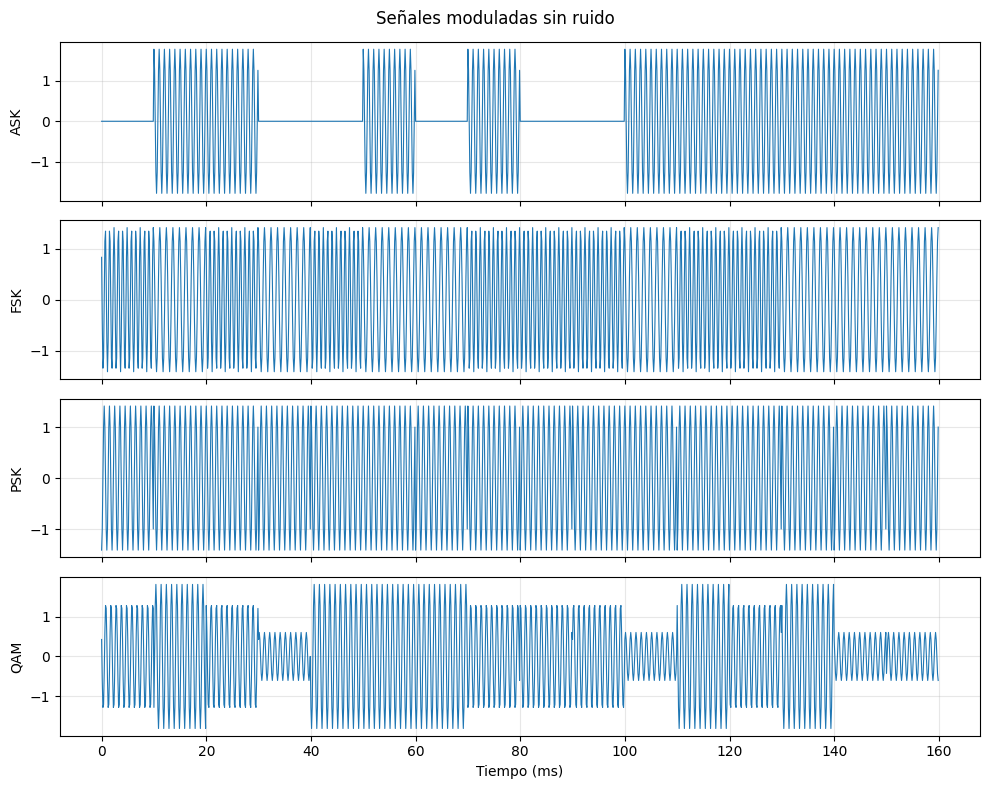

In [ ]:
# Gráfica de las 4 señales sin ruido
fig_MDCGA, axs_MDCGA = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
for ax_MDCGA, mod_MDCGA in zip(axs_MDCGA, MODULACIONES_MDCGA):
    ax_MDCGA.plot(t_MDCGA*1000,
                  generar_senal_MDCGA(mod_MDCGA, rng_MDCGA, fase_aleatoria_MDCGA=False),
                  lw=0.8)
    ax_MDCGA.set_ylabel(mod_MDCGA)
    ax_MDCGA.grid(alpha=0.3)
axs_MDCGA[-1].set_xlabel("Tiempo (ms)")
fig_MDCGA.suptitle("Señales moduladas sin ruido")
plt.tight_layout()
plt.show()

## 1.5 Añadir ruido (AWGN)
Después hice la función que le agrega ruido a las señales. AWGN es ruido blanco gaussiano aditivo, o sea que a la señal se le *suma* un ruido con distribución normal, y así simulo un canal real.

Para controlar cuánto ruido se agrega usé el SNR (relación señal-ruido). Como mis señales tienen potencia 1, la potencia del ruido la calculé con:

**Potencia del ruido = 1 / 10^(SNR/10)**

Con un SNR alto (20 dB) casi no hay ruido y con un SNR bajo (−10 dB) hay muchísimo. Puse este paso antes del 1.4 porque la generación del dataset necesita esta función.

In [ ]:
# ---------- 1.5 Ruido AWGN ----------
def agregar_awgn_MDCGA(x_MDCGA, snr_db_MDCGA, rng_MDCGA):
    potencia_senal_MDCGA = np.mean(x_MDCGA**2)
    potencia_ruido_MDCGA = potencia_senal_MDCGA / (10**(snr_db_MDCGA/10))
    return x_MDCGA + rng_MDCGA.normal(0, np.sqrt(potencia_ruido_MDCGA), size=x_MDCGA.shape)

Aquí tomé la misma señal PSK y le puse distintos niveles de ruido (20, 10, 0 y −10 dB). Se nota cómo conforme baja el SNR la señal se va perdiendo, y a −10 dB ya casi no se distingue.

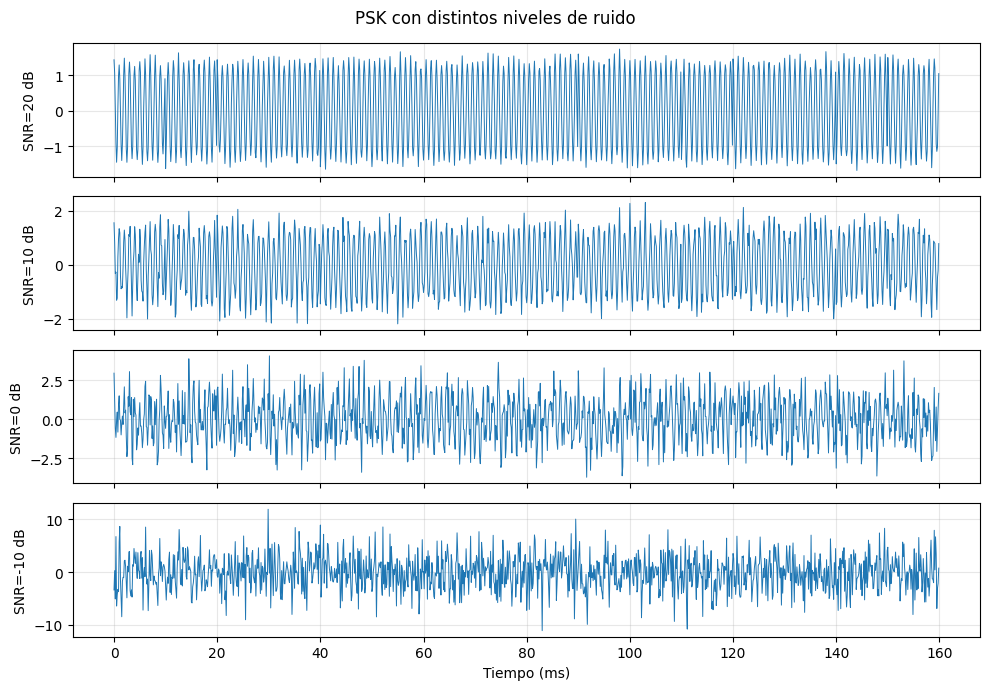

In [ ]:
# Gráfica: PSK con distintos SNR
niveles_demo_MDCGA = [20, 10, 0, -10]
x_limpia_MDCGA = generar_senal_MDCGA("PSK", rng_MDCGA, fase_aleatoria_MDCGA=False)
fig_MDCGA, axs_MDCGA = plt.subplots(len(niveles_demo_MDCGA), 1, figsize=(10, 7), sharex=True)
for ax_MDCGA, snr_MDCGA in zip(axs_MDCGA, niveles_demo_MDCGA):
    ax_MDCGA.plot(t_MDCGA*1000, agregar_awgn_MDCGA(x_limpia_MDCGA, snr_MDCGA, rng_MDCGA), lw=0.7)
    ax_MDCGA.set_ylabel(f"SNR={snr_MDCGA} dB")
    ax_MDCGA.grid(alpha=0.3)
axs_MDCGA[-1].set_xlabel("Tiempo (ms)")
fig_MDCGA.suptitle("PSK con distintos niveles de ruido")
plt.tight_layout()
plt.show()

## 1.4 Generar el conjunto de datos
Para armar el dataset recorrí cada una de las 4 modulaciones, y para cada una usé 7 niveles de SNR (−10, −5, 0, 5, 10, 15 y 20 dB) con 200 señales por nivel. Así obtuve **1,400 muestras por modulación** y **5,600 en total**, con lo que cumplo el mínimo de 1,000 por modulación que pide el proyecto.

De cada señal guardé su forma de onda, su etiqueta (0 = ASK, 1 = FSK, 2 = PSK, 3 = QAM) y su nivel de SNR. Guardé el SNR porque lo voy a necesitar en la Fase 3 para hacer la gráfica de precisión contra ruido. También normalicé cada señal después de agregarle el ruido.

In [ ]:
# ---------- 1.4 Generar el dataset ----------
SNR_LIST_MDCGA = [-10, -5, 0, 5, 10, 15, 20]   # dB
N_POR_SNR_MDCGA = 200                          # 200 x 7 = 1400 muestras por modulación

X_MDCGA, y_MDCGA, snr_arr_MDCGA = [], [], []
for etiqueta_MDCGA, mod_MDCGA in enumerate(MODULACIONES_MDCGA):
    for snr_MDCGA in SNR_LIST_MDCGA:
        for _ in range(N_POR_SNR_MDCGA):
            x_MDCGA = generar_senal_MDCGA(mod_MDCGA, rng_MDCGA)
            x_MDCGA = agregar_awgn_MDCGA(x_MDCGA, snr_MDCGA, rng_MDCGA)
            x_MDCGA = x_MDCGA / np.std(x_MDCGA)      # normalización por muestra
            X_MDCGA.append(x_MDCGA)
            y_MDCGA.append(etiqueta_MDCGA)
            snr_arr_MDCGA.append(snr_MDCGA)

X_MDCGA = np.array(X_MDCGA, dtype=np.float32)[..., np.newaxis]   # (N, 1280, 1)
y_MDCGA = np.array(y_MDCGA)
snr_arr_MDCGA = np.array(snr_arr_MDCGA)

print("X:", X_MDCGA.shape, "| y:", y_MDCGA.shape)
for i_MDCGA, m_MDCGA in enumerate(MODULACIONES_MDCGA):
    print(f"  {m_MDCGA}: {np.sum(y_MDCGA == i_MDCGA)} muestras")

X: (5600, 1280, 1) | y: (5600,)
  ASK: 1400 muestras
  FSK: 1400 muestras
  PSK: 1400 muestras
  QAM: 1400 muestras


## 1.6 Separación de datos (80% entrenamiento / 20% prueba)
Por último dividí el dataset en dos grupos: 80% para entrenamiento (4,480 muestras) y 20% para prueba (1,120 muestras). La red va a aprender con los datos de entrenamiento, y con los de prueba voy a evaluarla con señales que nunca vio, para comprobar que sí aprendió y no nada más memorizó.

Usé `stratify` para que los dos grupos tengan la misma proporción de modulaciones y de niveles de SNR. También convertí las etiquetas a formato *one-hot* (por ejemplo, PSK queda como [0, 0, 1, 0]), porque es el formato que pide la función de pérdida `categorical_crossentropy` que voy a usar en la Fase 2.

In [ ]:
# ---------- 1.6 Separación de datos (80% / 20%) ----------
estrato_MDCGA = y_MDCGA * 100 + (snr_arr_MDCGA + 20)

(X_train_MDCGA, X_test_MDCGA, y_train_MDCGA, y_test_MDCGA,
 snr_train_MDCGA, snr_test_MDCGA) = train_test_split(
    X_MDCGA, y_MDCGA, snr_arr_MDCGA,
    test_size=0.20, random_state=SEED_MDCGA, stratify=estrato_MDCGA
)

y_train_oh_MDCGA = np.eye(len(MODULACIONES_MDCGA))[y_train_MDCGA]
y_test_oh_MDCGA  = np.eye(len(MODULACIONES_MDCGA))[y_test_MDCGA]

print(f"Entrenamiento: {X_train_MDCGA.shape[0]} muestras")
print(f"Prueba:        {X_test_MDCGA.shape[0]} muestras")

Entrenamiento: 4480 muestras
Prueba:        1120 muestras


Guardé el dataset en un archivo `.npz` para poder usarlo en las siguientes fases sin tener que generarlo otra vez.

In [ ]:
# ---------- Guardar el dataset ----------
np.savez_compressed(
    "dataset_modulaciones.npz",
    X_train=X_train_MDCGA, y_train=y_train_MDCGA, y_train_oh=y_train_oh_MDCGA, snr_train=snr_train_MDCGA,
    X_test=X_test_MDCGA,   y_test=y_test_MDCGA,   y_test_oh=y_test_oh_MDCGA,   snr_test=snr_test_MDCGA,
    clases=np.array(MODULACIONES_MDCGA), fs=fs_MDCGA, fc=fc_MDCGA, Rs=Rs_MDCGA
)
print("Dataset guardado: dataset_modulaciones.npz")

Dataset guardado: dataset_modulaciones.npz


Finalmente, grafiqué un ejemplo de cada modulación del dataset ya con ruido (SNR = 10 dB) y normalizado, para ver cómo le van a llegar los datos a la red neuronal.

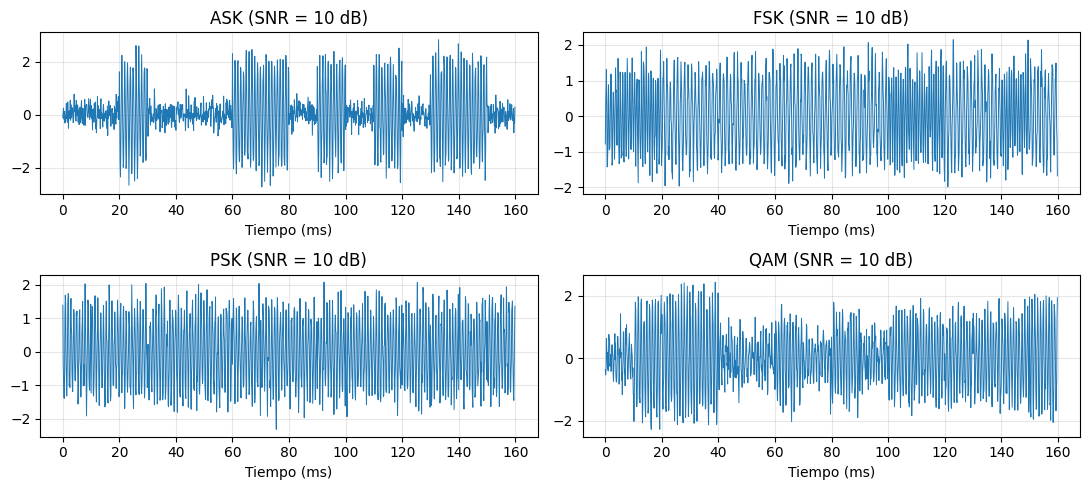

In [ ]:
# ---------- Ejemplos finales del dataset ----------
fig_MDCGA, axs_MDCGA = plt.subplots(2, 2, figsize=(11, 5))
for ax_MDCGA, (i_MDCGA, mod_MDCGA) in zip(axs_MDCGA.ravel(), enumerate(MODULACIONES_MDCGA)):
    idx_MDCGA = np.where((y_train_MDCGA == i_MDCGA) & (snr_train_MDCGA == 10))[0][0]
    ax_MDCGA.plot(t_MDCGA*1000, X_train_MDCGA[idx_MDCGA, :, 0], lw=0.7)
    ax_MDCGA.set_title(f"{mod_MDCGA} (SNR = 10 dB)")
    ax_MDCGA.set_xlabel("Tiempo (ms)")
    ax_MDCGA.grid(alpha=0.3)
plt.tight_layout()
plt.show()

---
#  Fase 2: Diseño y Entrenamiento del Modelo
**Autor:** MDCGA

En esta fase diseñé y entrené la red neuronal convolucional que va a clasificar las señales (ASK, FSK, PSK o QAM) usando el dataset que generé en la Fase 1. *(Este cuaderno sigue desde la Fase 1, por eso uso directamente las variables que ya creé: `X_train_MDCGA`, `y_train_oh_MDCGA`, etc.)*

## 2.1 Investigar arquitecturas
Investigué por qué las redes convolucionales (CNN) sirven para analizar señales. Lo que entendí es lo siguiente:

- Una capa convolucional pasa pequeños filtros a lo largo de la señal y detecta **patrones locales**, por ejemplo un cambio de amplitud, un salto de fase o un cambio de frecuencia. Esos patrones son justo lo que distingue a cada modulación.
- Como el mismo filtro se usa en toda la señal, la red detecta el patrón **sin importar en qué parte aparezca**. Esto es útil porque los bits son aleatorios y los cambios pueden ocurrir en cualquier símbolo.
- Usa **menos parámetros** que una red totalmente conectada, y aprende sola las características, sin que yo tenga que programarlas a mano.

Hay dos formas comunes de usarlas con señales: transformarlas a imágenes (espectrogramas) y usar una CNN 2D, o usar directamente la forma de onda con una **CNN 1D**. Yo elegí la **1D-CNN** porque mi dataset ya tiene las señales como series de tiempo de 1280 muestras, así que no necesito convertirlas.

## 2.2 Diseñar el modelo
Construí la red con Keras (`Sequential`) siguiendo la sugerencia del proyecto, y le agregué capas de `MaxPooling1D` y `Dropout`:

1. **Entrada:** una señal de 1280 muestras con 1 canal.
2. **Conv1D (32 filtros, tamaño 7, ReLU)** y **MaxPooling1D (4):** detecta patrones básicos y reduce la longitud de la señal.
3. **Conv1D (64 filtros, tamaño 5, ReLU)** y **MaxPooling1D (4):** detecta patrones más complejos.
4. **Flatten:** convierte el resultado en un vector para poder usar capas densas.
5. **Dense (64, ReLU)** con **Dropout (0.3):** combina la información; el Dropout apaga neuronas al azar para evitar que la red memorice.
6. **Dense (4, Softmax):** una neurona por modulación; la salida son las probabilidades de que sea ASK, FSK, PSK o QAM.

El MaxPooling lo agregué para que el Flatten no genere un vector gigante (de 82,000 valores a 5,120), así el modelo es más rápido de entrenar.

In [ ]:
# ---------- 2.2 Diseñar el modelo ----------
from tensorflow import keras
from tensorflow.keras import layers

def construir_modelo_MDCGA(longitud_MDCGA, n_clases_MDCGA):
    modelo_MDCGA = keras.Sequential([
        keras.Input(shape=(longitud_MDCGA, 1)),

        layers.Conv1D(32, kernel_size=7, activation="relu", padding="same"),
        layers.MaxPooling1D(pool_size=4),

        layers.Conv1D(64, kernel_size=5, activation="relu", padding="same"),
        layers.MaxPooling1D(pool_size=4),

        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(n_clases_MDCGA, activation="softmax"),
    ], name="detective_de_senales_MDCGA")
    return modelo_MDCGA

modelo_MDCGA = construir_modelo_MDCGA(N_SAMPLES_MDCGA, len(MODULACIONES_MDCGA))
modelo_MDCGA.summary()

Model: "detective_de_senales_MDCGA"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 1280, 32)       │           256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 320, 32)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 320, 64)        │        10,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 80, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5120)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       327,744 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 338,564 (1.29 MB)

 Trainable params: 338,564 (1.29 MB)

 Non-trainable params: 0 (0.00 B)

## 2.3 Compilar el modelo
Para compilar elegí:
- **Optimizador Adam:** ajusta la velocidad de aprendizaje automáticamente y funciona bien en la mayoría de los casos.
- **Pérdida `categorical_crossentropy`:** es la adecuada para clasificación de varias clases con etiquetas *one-hot* (las que preparé en la Fase 1).
- **Métrica `accuracy`:** el porcentaje de señales que clasifica correctamente.

In [ ]:
# ---------- 2.3 Compilar el modelo ----------
modelo_MDCGA.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

## 2.4 Entrenar el modelo
Entrené con `.fit()` usando el conjunto de entrenamiento (80% de los datos). Usé **20 épocas** (20 pasadas completas por los datos) y lotes de **64 señales**. Además aparté el 20% del entrenamiento como **validación**, para ver durante el entrenamiento si la red está generalizando o solo memorizando. El conjunto de prueba no lo toqué, lo dejo para la Fase 3.

Después grafiqué la precisión y la pérdida por época para monitorear el aprendizaje: la precisión debe subir y la pérdida debe bajar.

In [ ]:
# ---------- 2.4 Entrenar el modelo ----------
historial_MDCGA = modelo_MDCGA.fit(
    X_train_MDCGA, y_train_oh_MDCGA,
    epochs=20,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

Epoch 1/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 7s 99ms/step - accuracy: 0.4662 - loss: 1.1258 - val_accuracy: 0.7042 - val_loss: 0.7879
Epoch 2/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 7s 128ms/step - accuracy: 0.6671 - loss: 0.7072 - val_accuracy: 0.8181 - val_loss: 0.5244
Epoch 3/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 99ms/step - accuracy: 0.7852 - loss: 0.5084 - val_accuracy: 0.8839 - val_loss: 0.3676
Epoch 4/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 9s 155ms/step - accuracy: 0.8474 - loss: 0.3763 - val_accuracy: 0.8460 - val_loss: 0.3899
Epoch 5/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 97ms/step - accuracy: 0.8683 - loss: 0.3205 - val_accuracy: 0.8627 - val_loss: 0.3333
Epoch 6/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 7s 125ms/step - accuracy: 0.8817 - loss: 0.2968 - val_accuracy: 0.9051 - val_loss: 0.2454
Epoch 7/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 9s 110ms/step - accuracy: 0.9182 - loss: 0.2237 - val_accuracy: 0.9051 - val_loss: 0.2414
Epoch 8/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 7s 124ms/step - accuracy: 0.9280 - loss: 0.1978 - val_accuracy: 0.917

Gráficas de precisión y pérdida durante el entrenamiento:

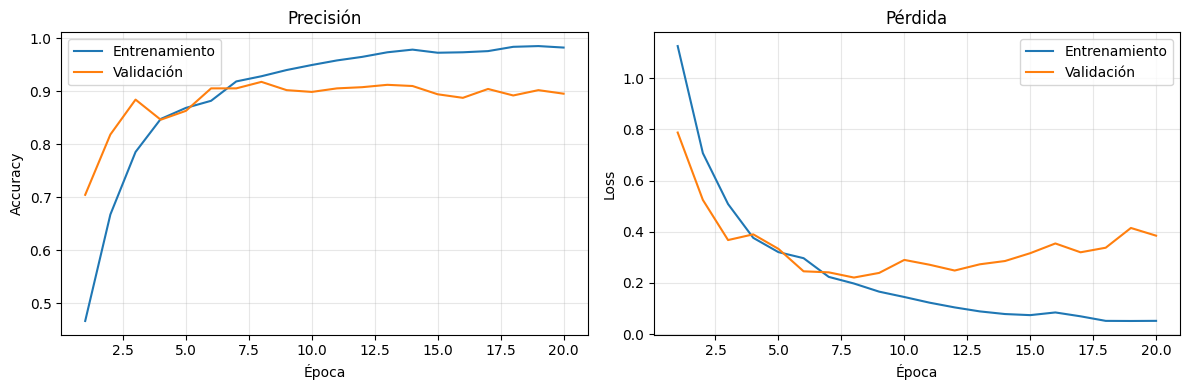

Precisión final de entrenamiento: 98.21%
Precisión final de validación:    89.51%


In [ ]:
# Gráficas del entrenamiento
h_MDCGA = historial_MDCGA.history
epocas_MDCGA = range(1, len(h_MDCGA["accuracy"]) + 1)

fig_MDCGA, (ax1_MDCGA, ax2_MDCGA) = plt.subplots(1, 2, figsize=(12, 4))

ax1_MDCGA.plot(epocas_MDCGA, h_MDCGA["accuracy"], label="Entrenamiento")
ax1_MDCGA.plot(epocas_MDCGA, h_MDCGA["val_accuracy"], label="Validación")
ax1_MDCGA.set_title("Precisión")
ax1_MDCGA.set_xlabel("Época")
ax1_MDCGA.set_ylabel("Accuracy")
ax1_MDCGA.legend()
ax1_MDCGA.grid(alpha=0.3)

ax2_MDCGA.plot(epocas_MDCGA, h_MDCGA["loss"], label="Entrenamiento")
ax2_MDCGA.plot(epocas_MDCGA, h_MDCGA["val_loss"], label="Validación")
ax2_MDCGA.set_title("Pérdida")
ax2_MDCGA.set_xlabel("Época")
ax2_MDCGA.set_ylabel("Loss")
ax2_MDCGA.legend()
ax2_MDCGA.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Precisión final de entrenamiento: {h_MDCGA['accuracy'][-1]:.2%}")
print(f"Precisión final de validación:    {h_MDCGA['val_accuracy'][-1]:.2%}")

## 2.5 Guardar el modelo
Por último exporté el modelo entrenado a un archivo `.keras` para no tener que volver a entrenarlo en las siguientes fases. Para comprobar que se guardó bien, lo volví a cargar y verifiqué que da las mismas predicciones.

In [ ]:
# ---------- 2.5 Guardar el modelo ----------
modelo_MDCGA.save("modelo_modulaciones_MDCGA.keras")
print("Modelo guardado: modelo_modulaciones_MDCGA.keras")

# Comprobación: cargarlo de nuevo y comparar predicciones
modelo_cargado_MDCGA = keras.models.load_model("modelo_modulaciones_MDCGA.keras")
pred_original_MDCGA = modelo_MDCGA.predict(X_test_MDCGA[:10], verbose=0)
pred_cargado_MDCGA = modelo_cargado_MDCGA.predict(X_test_MDCGA[:10], verbose=0)
print("¿Predicciones iguales?", np.allclose(pred_original_MDCGA, pred_cargado_MDCGA))

# (Opcional, solo en Colab) descargarlo a tu computadora:
# from google.colab import files
# files.download("modelo_modulaciones_MDCGA.keras")

Modelo guardado: modelo_modulaciones_MDCGA.keras
¿Predicciones iguales? True


Precisión global en prueba: 89.46%


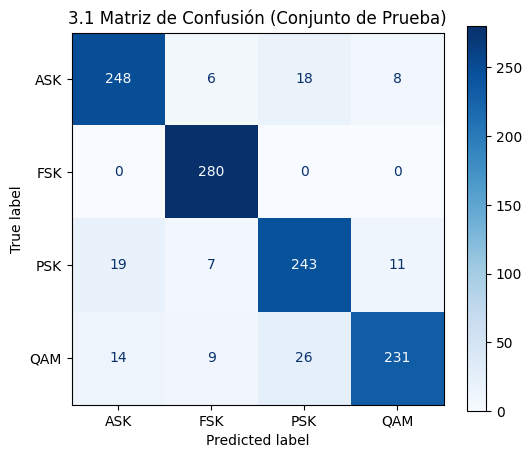


--- 3.2 Precisión por nivel de SNR ---
SNR = -10 dB -> Accuracy: 56.88%
SNR =  -5 dB -> Accuracy: 78.12%
SNR =   0 dB -> Accuracy: 94.38%
SNR =   5 dB -> Accuracy: 99.38%
SNR =  10 dB -> Accuracy: 99.38%
SNR =  15 dB -> Accuracy: 98.75%
SNR =  20 dB -> Accuracy: 99.38%


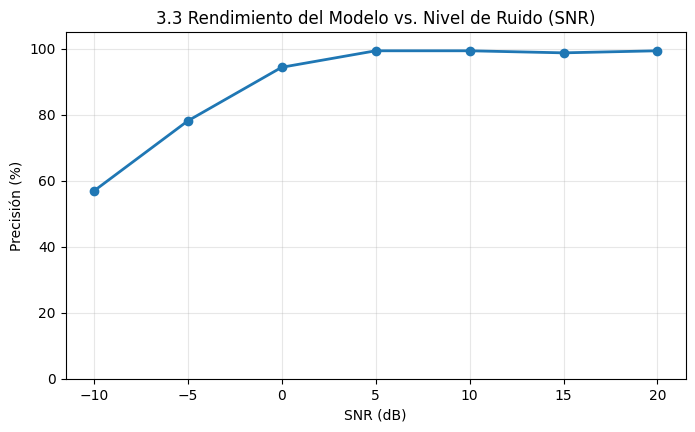


--- 3.4 Precisión por modulación ---
ASK   : 88.57%
FSK   : 100.00%
PSK   : 86.79%
QAM   : 82.50%


In [ ]:
# =====================================================================
# FASE 3: Evaluación y Robustez del Modelo
# =====================================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score
from tensorflow import keras

# Cargar datos y modelo guardados si inicias sesión nueva
data_MDCGA = np.load("dataset_modulaciones.npz")
X_test_MDCGA = data_MDCGA["X_test"]
y_test_MDCGA = data_MDCGA["y_test"]
snr_test_MDCGA = data_MDCGA["snr_test"]
clases_MDCGA = data_MDCGA["clases"]

modelo_MDCGA = keras.models.load_model("modelo_modulaciones_MDCGA.keras")

# Predicciones en todo el conjunto de prueba
probs_MDCGA = modelo_MDCGA.predict(X_test_MDCGA, verbose=0)
y_pred_MDCGA = np.argmax(probs_MDCGA, axis=1)

acc_global_MDCGA = accuracy_score(y_test_MDCGA, y_pred_MDCGA)
print(f"Precisión global en prueba: {acc_global_MDCGA:.2%}")

# 3.1 Matriz de Confusión
cm_MDCGA = confusion_matrix(y_test_MDCGA, y_pred_MDCGA)
disp_MDCGA = ConfusionMatrixDisplay(confusion_matrix=cm_MDCGA, display_labels=clases_MDCGA)
fig_MDCGA, ax_MDCGA = plt.subplots(figsize=(6, 5))
disp_MDCGA.plot(ax=ax_MDCGA, cmap="Blues", values_format="d")
plt.title("3.1 Matriz de Confusión (Conjunto de Prueba)")
plt.show()

# 3.2 y 3.3 Prueba de estrés por SNR y Gráfica de Rendimiento
snrs_unicos_MDCGA = np.sort(np.unique(snr_test_MDCGA))
accs_por_snr_MDCGA = []

print("\n--- 3.2 Precisión por nivel de SNR ---")
for s_MDCGA in snrs_unicos_MDCGA:
    mask_MDCGA = (snr_test_MDCGA == s_MDCGA)
    acc_s_MDCGA = accuracy_score(y_test_MDCGA[mask_MDCGA], y_pred_MDCGA[mask_MDCGA])
    accs_por_snr_MDCGA.append(acc_s_MDCGA * 100)
    print(f"SNR = {s_MDCGA:>3} dB -> Accuracy: {acc_s_MDCGA:.2%}")

plt.figure(figsize=(8, 4.5))
plt.plot(snrs_unicos_MDCGA, accs_por_snr_MDCGA, marker="o", linewidth=2)
plt.title("3.3 Rendimiento del Modelo vs. Nivel de Ruido (SNR)")
plt.xlabel("SNR (dB)")
plt.ylabel("Precisión (%)")
plt.ylim(0, 105)
plt.grid(True, alpha=0.3)
plt.show()

# 3.4 Precisión por modulación (análisis de errores)
print("\n--- 3.4 Precisión por modulación ---")
for idx_c, nombre_c in enumerate(clases_MDCGA):
    mask_c = (y_test_MDCGA == idx_c)
    acc_c = accuracy_score(y_test_MDCGA[mask_c], y_pred_MDCGA[mask_c])
    print(f"{nombre_c:<6}: {acc_c:.2%}")